In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import models, transforms
from skimage import data
from PIL import Image

def show_images(titles, images, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i in range(len(images)):
        plt.subplot(1, len(images), i + 1)
        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

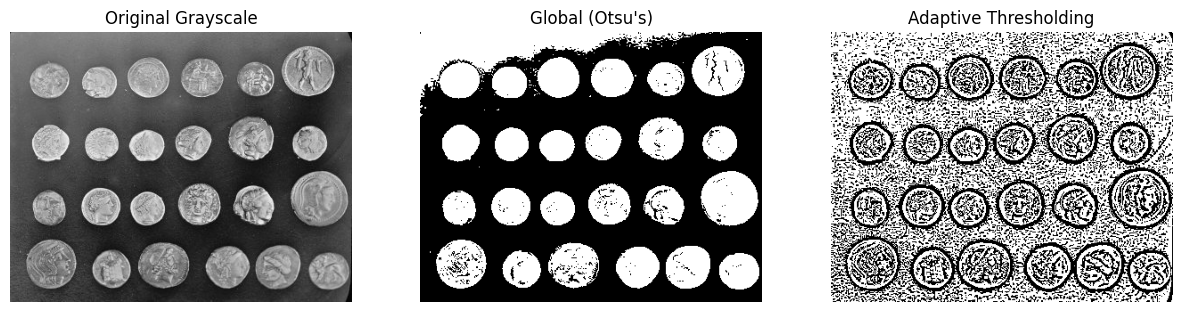

In [ ]:
# --- 1. Thresholding Segmentation ---
# Load the built-in coins image directly from scikit-image's memory
img_gray = data.coins()

# Global Thresholding (Otsu's Method)
ret, thresh_otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Adaptive Thresholding
thresh_adapt = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, 11, 2)

show_images(['Original Grayscale', "Global (Otsu's)", 'Adaptive Thresholding'],
            [img_gray, thresh_otsu, thresh_adapt])

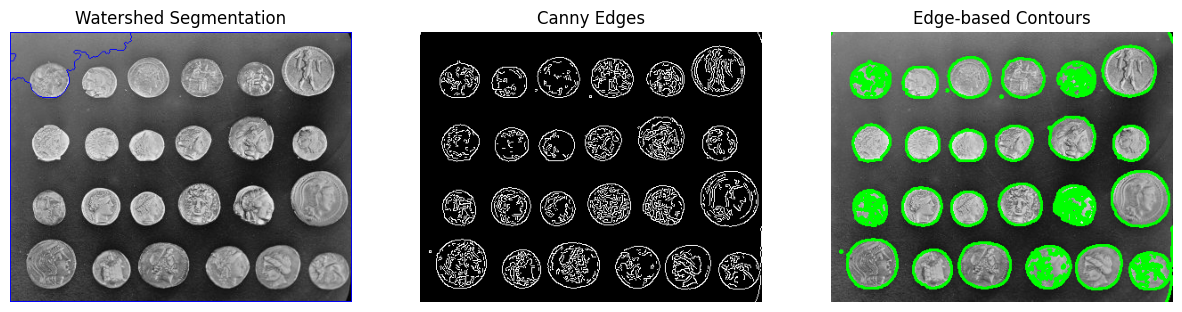

In [ ]:
# --- 2. Region-Based Segmentation (Watershed) ---
# Convert the grayscale coins to color so we can draw red boundary lines
img_color = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2BGR)

# Noise removal
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh_otsu, cv2.MORPH_OPEN, kernel, iterations=2)

# Sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)
# Finding sure foreground area
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labelling
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed Algorithm
markers = cv2.watershed(img_color, markers)
img_watershed = img_color.copy()
img_watershed[markers == -1] = [255, 0, 0] # Mark boundaries in red

# --- 3. Edge-Based Segmentation ---
# Apply Canny Edge Detector
edges = cv2.Canny(img_gray, 100, 200)

# Find and draw contours
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
img_contours = img_color.copy()
cv2.drawContours(img_contours, contours, -1, (0, 255, 0), 2)

show_images(['Watershed Segmentation', 'Canny Edges', 'Edge-based Contours'],
            [img_watershed, edges, img_contours])

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 141MB/s]


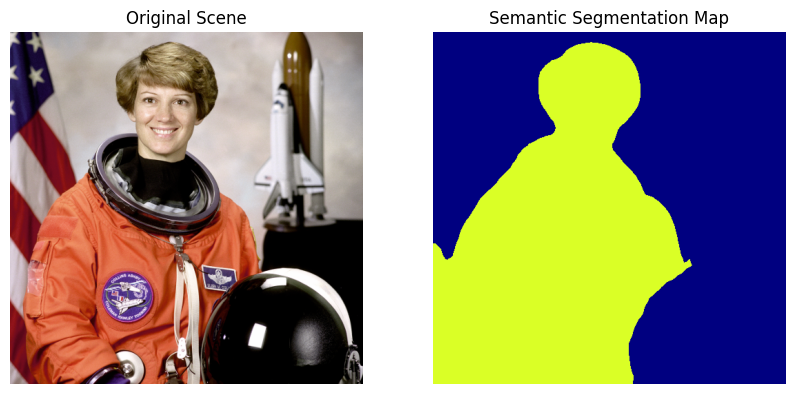

In [ ]:
# --- 4. Semantic Segmentation ---
model = models.segmentation.deeplabv3_resnet50(weights=models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT)
model.eval()

scene_rgb = data.astronaut()
img_scene = Image.fromarray(scene_rgb)

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
input_tensor = preprocess(img_scene)
input_batch = input_tensor.unsqueeze(0)

# Perform inference
with torch.no_grad():
    output = model(input_batch)['out'][0]
output_predictions = output.argmax(0).byte().cpu().numpy()

# Apply a color map for visualization
scene_cv2 = cv2.cvtColor(scene_rgb, cv2.COLOR_RGB2BGR)
colored_segmentation = cv2.applyColorMap(output_predictions * 10, cv2.COLORMAP_JET)

show_images(['Original Scene', 'Semantic Segmentation Map'],
            [scene_cv2, colored_segmentation], figsize=(10, 5))